In [ ]:
#health Risk Classifictaion Project
#Name: Syed Furqan Hussain
#Roll No: 24F-AI-110

In [1]:
#importing the libraries

import numpy as np
import pandas as pd

#reading csv now

df = pd.read_csv("diabetes.csv")

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [2]:
#checking for missing values

df.isna().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [6]:
#no missing values
# lets normailize data, but fisrt we split it into train and test
# importing the lib

from sklearn.model_selection import train_test_split

# separating features

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# splitting dataset

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y)

#now lets normalize
# importing the scaler

from sklearn.preprocessing import MinMaxScaler

# puting the function inside the scaler variable

scaler = MinMaxScaler()

# fitting X train but not using .fit_ for X test bc it leaks our data during testing

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [27]:
# lets work on the 1st model (SVM)
# importing the model
from sklearn.svm import SVC

# creating the SVM model

model1 = SVC()

# fitting the model

model1.fit(X_train, y_train)

# making preddiction

y_predm1 = model1.predict(X_test)


In [28]:
# checking the accuracy for model 1 SVM

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# lets check the accuracy and other metrices

m1_precision = precision_score(y_test, y_predm1)

m1_recall = recall_score(y_test, y_predm1)

m1_f1 = f1_score(y_test, y_predm1)

m1_acc = accuracy_score(y_test, y_predm1)

print("Precision by SVM:", m1_precision)
print("Recall by SVM:", m1_recall)
print("F1 Score by SVM:", m1_f1)
print("Accuracyby SVM:", m1_acc)

#creating a confusion matrix

from sklearn.metrics import confusion_matrix

cm1 = confusion_matrix(y_test, y_predm1)

print("Confusion Matrix:\n", cm1)

Precision by SVM: 0.7037037037037037
Recall by SVM: 0.7037037037037037
F1 Score by SVM: 0.7037037037037037
Accuracyby SVM: 0.7922077922077922
Confusion Matrix:
 [[84 16]
 [16 38]]


In [29]:
# now lets work on model 2 (Decision Tree)

# importing the model

from sklearn.tree import DecisionTreeClassifier

# lets create the model 2 for decision tree

model2 = DecisionTreeClassifier()

# fitting the model

model2.fit(X_train, y_train)

# making prediction

y_predm2 = model2.predict(X_test)


In [30]:
# checking the accuracy for model 2 Decision Tree

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# lets check the accuracy and other metrices

m2_precision = precision_score(y_test, y_predm2)

m2_recall = recall_score(y_test, y_predm2)

m2_f1 = f1_score(y_test, y_predm2)

m2_acc = accuracy_score(y_test, y_predm2)

print("Precision by Decision Tree Classifier:", m2_precision)
print("Recall by Decision Tree Classifier:", m2_recall)
print("F1 Score by Decision Tree Classifier:", m2_f1)
print("Accuracy by Decision Tree Classifier:", m2_acc)

#creating a confusion matrix

from sklearn.metrics import confusion_matrix

cm2 = confusion_matrix(y_test, y_predm2)

print("Confusion Matrix:\n", cm2)

Precision by Decision Tree Classifier: 0.7592592592592593
Recall by Decision Tree Classifier: 0.7592592592592593
F1 Score by Decision Tree Classifier: 0.7592592592592593
Accuracy by Decision Tree Classifier: 0.8311688311688312
Confusion Matrix:
 [[87 13]
 [13 41]]


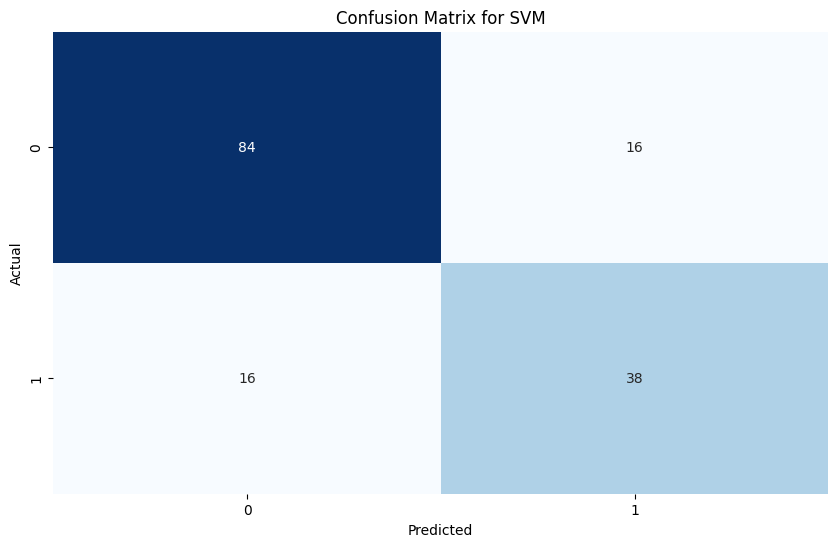

In [31]:
# lets compare both and visualize

# importing the required libraries

import matplotlib.pyplot as plt
import seaborn as sns

# creating heatmap for the 1st model SVM

plt.figure(figsize=(10, 6))
sns.heatmap(
    confusion_matrix(y_test, y_predm1),
    annot=True,
    cbar=False,
    cmap="Blues",
    fmt="d"
)

# plotting the heatmap

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for SVM")
plt.show()

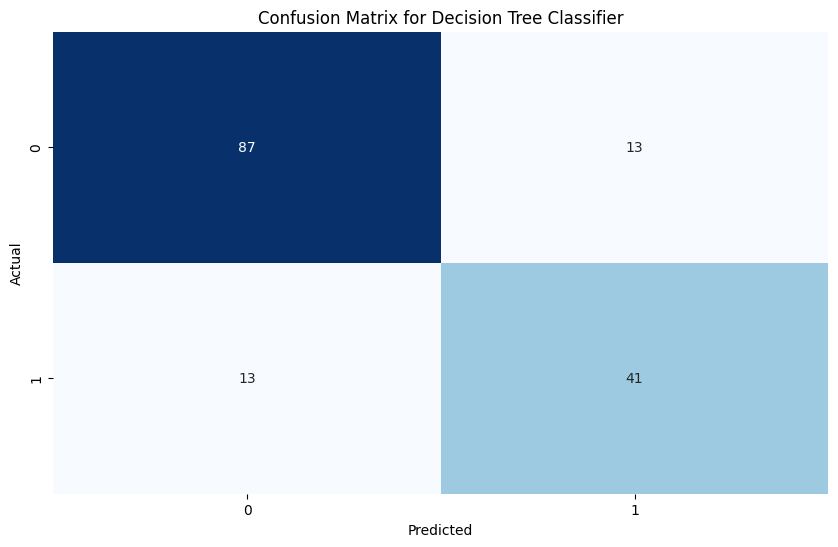

In [32]:
# creating heatmap for the 1st model Decision Tree Classifier

plt.figure(figsize=(10, 6))
sns.heatmap(
    confusion_matrix(y_test, y_predm2),
    annot=True,
    cbar=False,
    cmap="Blues",
    fmt="d"
)

# plotting the heatmap

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix for Decision Tree Classifier")
plt.show()